# Постановка задачи


**Цель работы:** исследование и обработка данных для повышения их качества.

**Краткое описание:** в лабораторной работе приводится поэтапный план изучения и обработки намеренно не предобработанных данных. Необходимо выполнить все этапы плана и оценить результаты преобразований.

# Данные



В папке [Data/lab3](https://drive.google.com/drive/folders/1437z7m5Ut4WUJOhJg1oZz13dtBpxgFKs?usp=share_link) расположена таблица `monster_com_job_sample.com` с данными о вакансиях. Также эти данные с описанием и примерами обработки можно найти на [kaggle](https://www.kaggle.com/code/ankkur13/perfect-dataset-to-get-the-hands-dirty/data#).

##### **Формат данных**

```
country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
United States of America,US,"",No,jobs.monster.com,"TeamSoft is seeing an IT Support Specialist to join our client in Madison, WI. The ideal candidate must have at least 6 years of experience in the field. They need to be familiar with a variety of the field's concepts, practices, and procedures as this position relies on extensive experience and judgment to plan and accomplish goals. Required Skills:вАҐ Call tracking softwareвАҐ Phone based technical supportвАҐ Problem documentation and communicationвАҐ Remote Desktop Management ToolsвАҐ Respond to customer requestsвАҐ General understanding of LANDeskвАҐ Microsoft Office 2007 SuiteFind out why TeamSoft is the Madison area's technology leader with over 200 IT consultants. Owned, operated, and managed by IT consultants, TeamSoft is the clear choice for your career. Join the TeamSoft family today!Did you know?вАҐ TeamSoft offers salaried options for many positions that include 5 weeks PTO and great benefits!вАҐ TeamSoft has been in business since 1996вАҐ TeamSoft's owners are local IT professionals who possess a wealth of experience in application development, business analysis, and project managementвАҐ TeamSoft's Recruiters are knowledgeable, friendly, and ready to help you make your next great career moveвАҐ TeamSoft offers a full benefits suite to all of our W2 consultants, including a 401k plan with a 100% vested 4% dollar for dollar matchвАҐ Our targeted selection process is designed to get to know your strengths and career interests and provide you with the best chance for success in your new positionвАҐ Our longest running consultant has been with us for 16 yearsвАҐ Consultants can participate in our charitable giving committee. To date, TeamSoft's charitable giving committee has donated over $100,000!TeamSoft is owned by local IT professionals. Our team also has deep experience with IT staffing. Our clients understand this and rely on our expertise. That is why TeamSoft is the Madison Area's largest privately owned IT consulting firm, with more than 200 current consultants! With over 50 active clients, TeamSoft will give you the greatest exposure to the widest range of IT careers.Our owners possess a combined 60+ years of IT consulting experience. Our recruiting and Account Management staff are very well-versed in our client markets. We get you. We know you. We know what you do every day. And we know what you deal with on the job.You take your career seriously and so do we. At TeamSoft you are not just a resume or number. Our goal is to create long-term partnerships with each of our consultants, and according to feedback from many of them, we are very good at this. Click HERE to see what our consultants have to say about working with TeamSoft.TeamSoft -- Promote yourself!TeamSoft is an equal employment opportunity employer functioning under an Affirmative Action Plan.",IT Support Technician Job in Madison,Full Time Employee,"Madison, WI 53702","",http://jobview.monster.com/it-support-technician-job-madison-wi-us-167855963.aspx?mescoid=1500134001001&jobPosition=20,"",IT/Software Development,11d599f229a80023d2f40e7c52cd941e
United States of America,US,"",No,jobs.monster.com,"The Wisconsin State Journal is seeking a flexible and motivated reporter/editor to lead its three-person business desk. WeвАЩre looking for an experienced journalist able to spot trends, be a watchdog and reflect the Madison areaвАЩs vibrant entrepreneurial community. This is a hybrid reporting and editing position that calls for a fleet-footed, multimedia storyteller able to maximize the newspaperвАЩs online presentation while also editing two sections a week. Candidates must have strong news judgment, be well versed in business news and trends and be able to quickly prioritize coverage.At least five yearsвАЩ experience reporting or editing for digital and print platforms desired. To be considered for the position, applicants must apply online.¬†As part of your online application, please attach five samples of your work or links to five recent stories.Wisconsin State Journal, 1901 Fish Hatchery Road, Madison, WI 53713Affirmative Action/Equal Opportunity Employer/Pre-employment drug testing appliesPI94338362Apply Here",Business Reporter/Editor Job in Madison,Full Time,"Madison, WI 53708",Printing and Publishing,http://jobview.monster.com/business-reporter-editor-job-madison-wi-us-167830105.aspx?mescoid=2700437001001&jobPosition=7,"","",e4cbb126dabf22159aff90223243ff2a
...
```

##### **Описание полей**
 - ```country``` — наименование страны;
 - ```country_code``` — код страны;
 - ```date_added``` — дата размещения вакансии;
 - ```has_expired``` — актуальность вакансии;
 - ```job_board``` — агрегатор вакансий, с которого собраны данные;
 - ```job_description``` — описание вакансии;
 - ```job_title``` — наименование должности;
 - ```job_type``` — вид занятости;
 - ```location``` — метоположение организации;
 - ```organization``` — наименование организации;
 - ```page_url``` — ссылка на страницу с вакансией;
 - ```salary``` — заработная плата;
 - ```sector``` — сфера деятельности;
 - ```uniq_id``` — уникальный идентификатор записи о вакансии.

# Понимание данных

In [1]:
import re
import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

# Модуль missingno необязателен: пропуски покажем через pandas.
try:
    import missingno as msno
except ImportError:
    msno = None

pd.set_option("display.max_columns", 20)


В датасете есть несколько столбцов, в каждой ячейке которых записано одно и то же значение. Есть столбцы, в которых формат записи значений не стандартизирован. А есть такие, где указана информация, не соответствующая названию столбца.

**Первый этап изучения данных** – понять, какие основные проблемы предстоит решить для каждого из столбцов. Для этого загрузите датасет и выведите случайные несколько строк из него. Постарайтесь понять, что из себя представляют данные в столбцах.

In [2]:
# Скачиваем данные, если рядом с ноутбуком их нет.
file = Path("monster_com_job_sample.csv")
if not file.exists():
    try:
        import gdown
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
        import gdown
    gdown.download(id="1s_X49sgW_HQQALThvElR8g4_Mp-VaWEo", output=str(file), quiet=False)

if not file.exists() or file.stat().st_size < 1000000:
    raise FileNotFoundError("Не удалось скачать CSV. Его можно загрузить вручную по ссылке из задания.")

data = pd.read_csv(file, low_memory=False)
print(f"Размер датасета: {data.shape[0]} строк, {data.shape[1]} столбцов")

# Сокращаем только вывод длинного текста, сами данные не меняем.
sample = data.sample(5, random_state=42).copy()
sample["job_description"] = sample["job_description"].str.slice(0, 100) + "..."
display(sample)


Размер датасета: 22000 строк, 14 столбцов


,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
13035,United States of America,US,NaN,No,jobs.monster.com,The QC Lead position requires an understanding...,Quality Control Lead Job in Santa Cruz,Full Time,"Santa Cruz, CA 95060",Manufacturing - Other,http://jobview.monster.com/Quality-Control-Lea...,NaN,Experienced (Non-Manager),c44af81ceb38d2b6fe00baf15d0dffe6
3115,United States of America,US,NaN,No,jobs.monster.com,JOB DESCRIPTION ...,Case Manager Job in Sunset Point,Full Time Employee,"Sunset Point, FL 33765",Healthcare Services,http://jobview.monster.com/Case-Manager-Job-Su...,NaN,Medical/Health,217600308ffc96a1a81eb8afba5ee522
8732,United States of America,US,NaN,No,jobs.monster.com,POSITION PURPOSE The Senior Manager Foundation...,Sr Manager,Full Time,"Atlanta, GA 30301",Retail,http://jobview.monster.com/sr-manager-foundati...,NaN,Manager (Manager/Supervisor of Staff),ef7db9ba10dd8bf7754ecf6ddd09a5aa
7591,United States of America,US,NaN,No,jobs.monster.com,GroundskeeperWest Knox Apart need a F/T Ground...,Groundskeeper Job in Knoxville,Full Time,"Knoxville, TN 37923",NaN,http://jobview.monster.com/Groundskeeper-Job-K...,NaN,NaN,cd3adb94fc647ca5ea3af731dc1da065
221,United States of America,US,NaN,No,jobs.monster.com,Combined Insurance is seeking Sales Agents to ...,Sales Agent Job in Knoxville,Full Time,"Knoxville, TN",Insurance,http://jobview.monster.com/Sales-Agent-Job-Kno...,NaN,NaN,ec59e3f419b851259632b757183d7365


**Таблица проблем, обнаруженных в исходном датасете**

Название столбца | Тип данных | Проблемы
--- | --- | ---
`country` | object | Одна страна во всех строках; для сравнения стран бесполезен.
`country_code` | object | Один код `US` во всех строках, повторяет информацию о стране.
`date_added` | object | Почти все даты пропущены; дата хранится текстом.
`has_expired` | object | Везде одно значение `No`, изменений актуальности нет.
`job_board` | object | Везде `jobs.monster.com`, признак постоянный.
`job_description` | object | Длинные неструктурированные тексты, повторения, иногда текст попадает в другие столбцы.
`job_title` | object | В названии должности иногда записан город или лишние слова.
`job_type` | object | Пропуски и разные способы записи одного типа занятости.
`location` | object | Город, штат и индекс перемешаны; иногда вместо адреса — описание вакансии.
`organization` | object | Пропуски; встречаются значения, больше похожие на сферу деятельности.
`page_url` | object | Ссылки уникальны, но по ним нельзя судить об уникальности самой вакансии.
`salary` | object | Много пропусков, разные валютные форматы и периоды, встречается текст вместо суммы.
`sector` | object | Пропуски; иногда данные похожи на `organization`.
`uniq_id` | object | Идентификатор уникален; для содержательного анализа вакансий сам по себе неинформативен.

Все исходные столбцы прочитаны pandas как `object` (текстовые значения), даже зарплата и дата.


### Оценка пустых ячеек в датасете

Выясните, в каких столбцах, строках и в каком количестве отсутствуют данные:
1. С помощью модуля `pandas` составьте таблицу, где каждому названию столбца будет сопоставлено общее количество ячеек и количество пустых ячеек.
2. Подсчитайте количество строк датасета, в которых пустыми являются более 75% ячеек.
3. Визуализируйте число пропусков в датасете с помощью модуля, построив столбчатую диаграмму. Для удобства можно воспользоваться модулем `missingno`.


,Всего строк,Пустых ячеек,"Доля пропусков, %"
country,22000,0,0.0
country_code,22000,0,0.0
date_added,22000,21878,99.4
has_expired,22000,0,0.0
job_board,22000,0,0.0
job_description,22000,0,0.0
job_title,22000,0,0.0
job_type,22000,1628,7.4
location,22000,0,0.0
organization,22000,6867,31.2


Строк с более чем 75% пропусков: 0


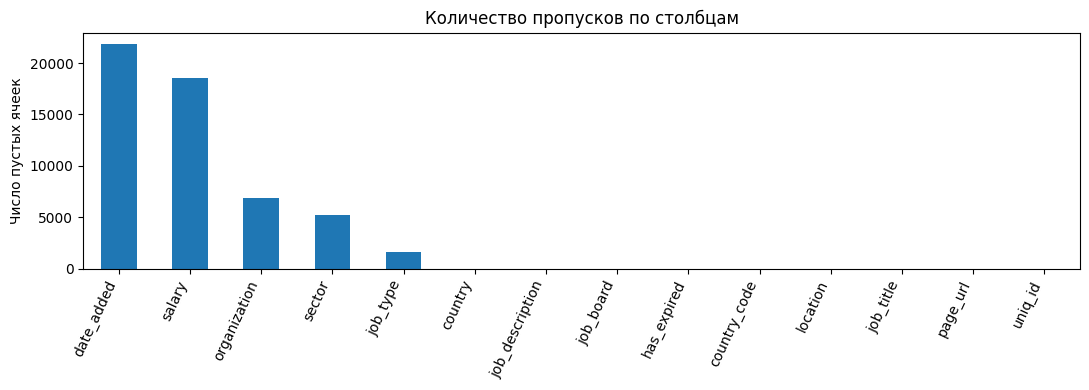

Вывод: чаще всего отсутствуют salary и date_added. Полностью удалять такие записи не стоит.


In [3]:
# Число строк и пропусков для каждого столбца
missing = pd.DataFrame({
    "Всего строк": len(data),
    "Пустых ячеек": data.isna().sum(),
    "Доля пропусков, %": (data.isna().mean() * 100).round(1)
})
display(missing)

many_missing = (data.isna().mean(axis=1) > 0.75).sum()
print("Строк с более чем 75% пропусков:", many_missing)

missing["Пустых ячеек"].sort_values(ascending=False).plot(kind="bar", figsize=(11, 4))
plt.title("Количество пропусков по столбцам")
plt.ylabel("Число пустых ячеек")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()
print("Вывод: чаще всего отсутствуют salary и date_added. Полностью удалять такие записи не стоит.")


Проверьте, как изменится размер датасета, если принять решение удалить все строки, где есть пустые значения. Сделайте выводы.

In [4]:
complete = data.dropna()
print("Исходная таблица:", data.shape)
print("После удаления всех строк с пропусками:", complete.shape)
print(f"Останется {len(complete) / len(data) * 100:.2f}% строк")
print("Вывод: удаление всех неполных строк приводит к слишком большой потере информации.")


Исходная таблица: (22000, 14)
После удаления всех строк с пропусками: (5, 14)
Останется 0.02% строк
Вывод: удаление всех неполных строк приводит к слишком большой потере информации.


### Первичная оценка данных в столбцах

Изучите данные в столбцах датасета, ответив на следующие вопросы:
1. Есть ли столбцы, в которых встречается всего одно значение? Как их можно использовать в анализе?
2. Есть ли такие значения, которые встречаются более чем в одном столбце?
3. Есть ли столбцы, данные в которых не соответствуют названию столбца?

In [5]:
# Столбцы, где всегда одно и то же значение
unique_counts = data.nunique(dropna=False)
print("Столбцы с одним значением:")
display(unique_counts[unique_counts == 1])

# Одинаковые записи в разных столбцах (organization и sector)
org_in_sector = data["organization"].isin(data["sector"].dropna()).sum()
sector_in_org = data["sector"].isin(data["organization"].dropna()).sum()
print("organization содержит значения из sector:", org_in_sector)
print("sector содержит значения из organization:", sector_in_org)
print("Подозрительно длинных значений в location (>120 символов):", data["location"].str.len().gt(120).sum())
print("Вывод: country, country_code, has_expired и job_board постоянны; location иногда содержит текст вакансии.")
print("Поля organization и sector местами содержат данные не своей категории.")


Столбцы с одним значением:


country         1
country_code    1
has_expired     1
job_board       1
dtype: int64

organization содержит значения из sector: 1082
sector содержит значения из organization: 24
Подозрительно длинных значений в location (>120 символов): 1232
Вывод: country, country_code, has_expired и job_board постоянны; location иногда содержит текст вакансии.
Поля organization и sector местами содержат данные не своей категории.


### Дублирование данных

Для поиска дублирующихся строк выполните следующие действия:
1. В таблице есть столбец `uniq_id`, значения которого, как сказано в описании данных, являются уникальными идентификаторами записей. Проверьте, действительно ли в этом столбце все значения различны.
2. Проверьте, есть ли в таблице другие столбцы, значения которых в каждой строке различны.
3. Если игнорировать столбцы, где все значения различны, найдутся ли такие строки, для которых значения по всем остальным столбцам будут совпадать?

Оцените результаты поиска дубликатов.

In [6]:
print("Уникальных uniq_id:", data["uniq_id"].nunique(), "из", len(data))

# Все значения в столбце уникальны, если число уникальных значений равно числу строк
unique_columns = data.columns[data.nunique(dropna=False) == len(data)].tolist()
print("Столбцы с полностью уникальными значениями:", unique_columns)

other_columns = data.columns.difference(unique_columns).tolist()
duplicate_rows = data.duplicated(subset=other_columns, keep=False)
print("Строк-дубликатов без уникальных столбцов:", duplicate_rows.sum())
display(data.loc[duplicate_rows, ["job_title", "location", "job_type", "organization", "sector"]].head())
print("Вывод: идентификаторы уникальны, но без них некоторые вакансии совпадают по всем остальным признакам.")


Уникальных uniq_id: 22000 из 22000
Столбцы с полностью уникальными значениями: ['page_url', 'uniq_id']


Строк-дубликатов без уникальных столбцов: 2078


,job_title,location,job_type,organization,sector
17,Pest Control Technician – Field Service Rep (E...,"Denver, CO","Full Time, Employee",Accounting and Auditing Services,Installation/Maintenance/Repair
27,Traveling Customer Training Professional Job i...,"Houston, TX 77040",Full Time Employee,AllComputer SoftwareComputer/IT Services,Customer Support/Client Care
47,Project Manager ( Z ) Job in Houston,"Houston, TX 77034",Full Time Employee,NaN,Business/Strategic Management
56,CASHIER Job in Houston,"Houston, TX",Full Time,Retail,Experienced (Non-Manager)
95,Scrum Master Job in Denver,"Denver, CO","Full Time, Employee",Computer/IT Services,IT/Software Development


Вывод: идентификаторы уникальны, но без них некоторые вакансии совпадают по всем остальным признакам.


# Практические задания

В этом разделе необходимо обработать значения в трех столбцах датасета: `location`, `salary` и `job_type`. Цель обработки – стандартизировать данные в каждом из столбцов так, чтобы их можно было анализировать.

### Задание 1

В задании 1 необходимо провести обработку столбца `location`.

#### Задание 1.1

В столбце `location` представлена информация о местоположении организации, в которой открыта вакансия. Каждое значение столбца `location` содержит информацию о городе, коде штата и почтовом индексе.

Однако не в каждой строке есть все три характеристики местоположения, а также могут встречаться разные комбинации из них, записанные в виде строки в произвольном порядке и с разными разделителями.

Например, может быть указан только код штата, только название города или только индекс. Могут быть указаны любые две характеристики из трех.

**Формулировка задания:**
1. Определите, какие форматы встречаются.
2. Напишите одно или несколько регулярных выражений для поиска выявленных форматов.
3. Визуализируйте количество найденных форматов на столбчатой или круговой диаграмме. Также покажите на ней количество строк, в которых формат определить не удалось. Какие форматы встречаются чаще всего?

Ознакомиться с теоретическим материалом по работе с регулярными выражениями можно [по ссылке](https://colab.research.google.com/drive/1eFHdmt9OROLEDJRNc2wNmz0gpE1O3sKU?usp=sharing).

,Количество
Формат,
город + штат + индекс,11361
город + штат,7171
Не определён,2623
город + индекс,328
только индекс,254
только штат,230
штат + индекс,21
только город,11
индекс + штат,1


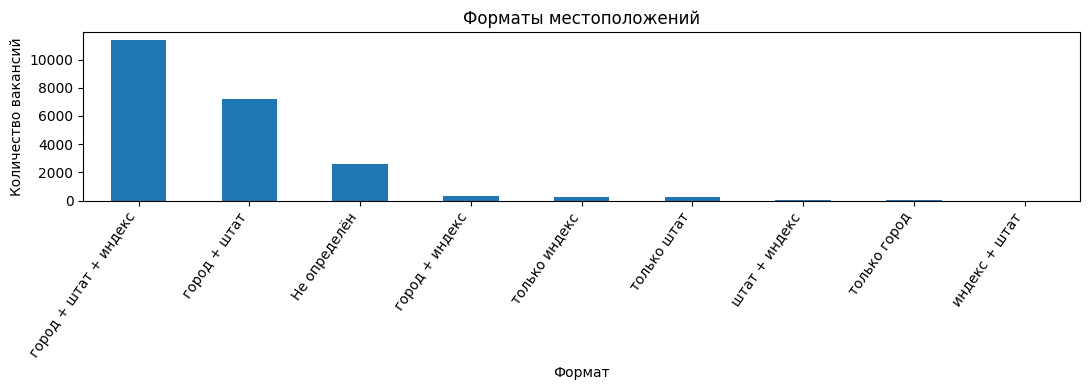

Самый частый формат: город + штат + индекс


In [7]:
# Регулярные выражения для основных вариантов записи местоположения.
STATE = r"(?:AL|AK|AZ|AR|CA|CO|CT|DE|FL|GA|HI|ID|IL|IN|IA|KS|KY|LA|ME|MD|MA|MI|MN|MS|MO|MT|NE|NV|NH|NJ|NM|NY|NC|ND|OH|OK|OR|PA|RI|SC|SD|TN|TX|UT|VT|VA|WA|WV|WI|WY|DC)"
CITY = r"[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{0,60}"
ZIP = r"\d{5}(?:-\d{4})?"

location_patterns = {
    "город + штат + индекс": rf"(?P<city>{CITY})\s*,\s*(?P<state>{STATE})\s+(?P<zip>{ZIP})",
    "город + штат": rf"(?P<city>{CITY})\s*,\s*(?P<state>{STATE})",
    "штат + индекс": rf"(?P<state>{STATE})[ ,]+(?P<zip>{ZIP})",
    "индекс + штат": rf"(?P<zip>{ZIP})[ ,]+(?P<state>{STATE})",
    "город + индекс": rf"(?P<city>{CITY})[ ,]+(?P<zip>{ZIP})",
    "только индекс": rf"(?P<zip>{ZIP})",
    "только штат": rf"(?P<state>{STATE})",
    "только город": rf"(?P<city>{CITY})"
}

location_text = data["location"].fillna("").astype(str).str.strip()
# Города, которые мы уже видели рядом с корректным кодом штата.
# Так не принимаем названия вакансий (например, "Testing Manager") за города.
known_cities = set(location_text.str.extract(
    rf"^({CITY})\s*,\s*{STATE}\b", flags=re.IGNORECASE
)[0].dropna().str.lower())
location_format = pd.Series("Не определён", index=data.index, name="Формат")

# Определяем первый подходящий формат (от более подробного к простому).
for label, pattern in location_patterns.items():
    mask = location_text.str.fullmatch(pattern, case=False).fillna(False)
    mask &= location_text.str.len() <= 80
    if label == "только город":
        mask &= location_text.str.lower().isin(known_cities)
        mask &= ~location_text.str.contains(r"(?i)\b(?:job|location|provided|remote|nationwide)\b")
    location_format.loc[mask & location_format.eq("Не определён")] = label

format_counts = location_format.value_counts()
display(format_counts.rename("Количество").to_frame())
format_counts.plot(kind="bar", figsize=(11, 4))
plt.title("Форматы местоположений")
plt.ylabel("Количество вакансий")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()
print("Самый частый формат:", format_counts.idxmax())


#### Задание 1.2

В большей части строк удалось извлечь данные из ячейки столбца `location`, но остались и такие, где это не получилось.

1. Вынесите в отдельный датасет записи, в которых не удалось определить формат записи информации о местоположении.
2. Данные о местоположении разделите на 3 столбца: город, код штата, почтовый индекс.

In [8]:
# Новые поля для хранения разобранного адреса.
clean = data.copy()
for column in ["город", "код штата", "почтовый индекс"]:
    clean[column] = pd.NA

for label, pattern in location_patterns.items():
    mask = location_format.eq(label)
    if not mask.any():
        continue
    parts = location_text.loc[mask].str.extract(f"^{pattern}$", flags=re.IGNORECASE)
    for original, target in [("city", "город"), ("state", "код штата"), ("zip", "почтовый индекс")]:
        if original in parts.columns:
            clean.loc[mask, target] = parts[original]

unparsed_locations = clean.loc[location_format.eq("Не определён")].copy()
print("Распознано форматов:", len(data) - len(unparsed_locations))
print("Не распознано:", len(unparsed_locations))
display(clean[["location", "город", "код штата", "почтовый индекс"]].sample(8, random_state=9))


Распознано форматов: 19377
Не распознано: 2623


,location,город,код штата,почтовый индекс
653,AZ,<NA>,AZ,<NA>
9984,"Secaucus, NJ 07094",Secaucus,NJ,07094
16231,"Connexion Systems & Engineering, a Boston base...",<NA>,<NA>,<NA>
2735,"Shreveport, LA 71101",Shreveport,LA,71101
112,"Dania, FL 33004",Dania,FL,33004
19039,"Philadelphia, PA",Philadelphia,PA,<NA>
16542,"Columbus, OH",Columbus,OH,<NA>
1747,Title: Business Operations Professional Locati...,<NA>,<NA>,<NA>


#### Задание 1.3

Рассмотрите отложенную часть выборки (ту, где не удалось данные из столбца `location` разделить на три поля) и сделайте выводы о возможности извлечь из данных город, код штата и почтовый индекс. Извлеките все, что возможно. Что невозможно – оставьте пустым.

In [9]:
# В оставшихся строках ищем явно указанные адреса внутри текста.
unknown = location_format.eq("Не определён")
raw = location_text.loc[unknown]

# Пример: "Location: Austin, TX" или фрагмент "Job in Austin, TX".
embedded = raw.str.extract(
    rf"(?:(?i:location)\s*:\s*|(?i:job in)\s+)(?P<city>{CITY})\s*,\s*(?P<state>{STATE})(?:\s+(?P<zip>{ZIP}))?"
)
for old, new in [("city", "город"), ("state", "код штата"), ("zip", "почтовый индекс")]:
    clean.loc[embedded.index, new] = clean.loc[embedded.index, new].fillna(embedded[old])

# Для коротких нестандартных строк пытаемся извлечь хотя бы штат или индекс.
short = raw[raw.str.len() <= 75]
state_found = short.str.extract(rf"\b({STATE})\b")[0]
zip_found = short.str.extract(rf"\b({ZIP})\b")[0]
clean.loc[short.index, "код штата"] = clean.loc[short.index, "код штата"].fillna(state_found)
clean.loc[short.index, "почтовый индекс"] = clean.loc[short.index, "почтовый индекс"].fillna(zip_found)

columns_address = ["город", "код штата", "почтовый индекс"]
print("Заполненные поля адреса:")
print(clean[columns_address].notna().sum())
print("Дополнительно удалось разобрать строк из отложенной части:",
      clean.loc[unknown, columns_address].notna().any(axis=1).sum())

still_unknown = clean.loc[clean[columns_address].isna().all(axis=1)]
print("Совсем без адресных данных осталось:", len(still_unknown))
display(still_unknown[["location"]].head(5).assign(location=lambda d: d["location"].str.slice(0, 100)))
print("Вывод: в слишком длинном тексте нельзя надёжно определить адрес; такие поля оставлены пустыми.")


Заполненные поля адреса:
город              19323
код штата          19411
почтовый индекс    12172
dtype: int64
Дополнительно удалось разобрать строк из отложенной части: 667
Совсем без адресных данных осталось: 1956


,location
2,DePuy Synthes Companies is a member of Johnson...
6,Contact name Tony Zerio
29,"Sr. Process Engineer, Manufacturing"
36,"RF System Technician, Field Service"
38,Bi-Lingual Editorial Strategist


Вывод: в слишком длинном тексте нельзя надёжно определить адрес; такие поля оставлены пустыми.


### Задание 2

В задании 2 необходимо провести обработку столбца `salary`.

#### Задание 2.1

В столбце `salary`, как и в `location`, данные не стандатизированы. В нем в основном можно встретить записи в следующих форматах:

* 10.00 - 20.00 &dollar; &sol;hour
* 10,000.00 - 20,000.00 &dollar; &sol;year
* &dollar;10.00 &sol;hour
* &dollar;10,000.00+ &sol;year
* Up to &dollar;20,000.00

Основные проблемы, которые стоит учесть при обработке форматов:
- В каждом из форматов может быть или не быть знака доллара.
- Может отсутствовать информация о периоде, за который указывается зарплата (`/hour` или `/year` в примерах).
- Зарплата может быть указана за месяц (`/month`) и за неделю (`/week`).
- В начале, конце и середине некоторых строк есть лишние пробелы, которые не стоит учитывать.

**Задание:**
1. Определите весь перечень встречающихся форматов и напишите одно или несколько регулярных выражений для их поиска.
2. Покажите на столбчатой диаграмме количество записей, содержащих каждый из форматов. Сделайте выводы.

,Количество
нет данных / без периода,18557
диапазон / year,1388
диапазон / hour,986
текст/нестандартная запись / без периода,392
диапазон / без периода,367
Up to / без периода,101
одна сумма / year,69
одна сумма / hour,69
одна сумма / без периода,50
диапазон / month,16


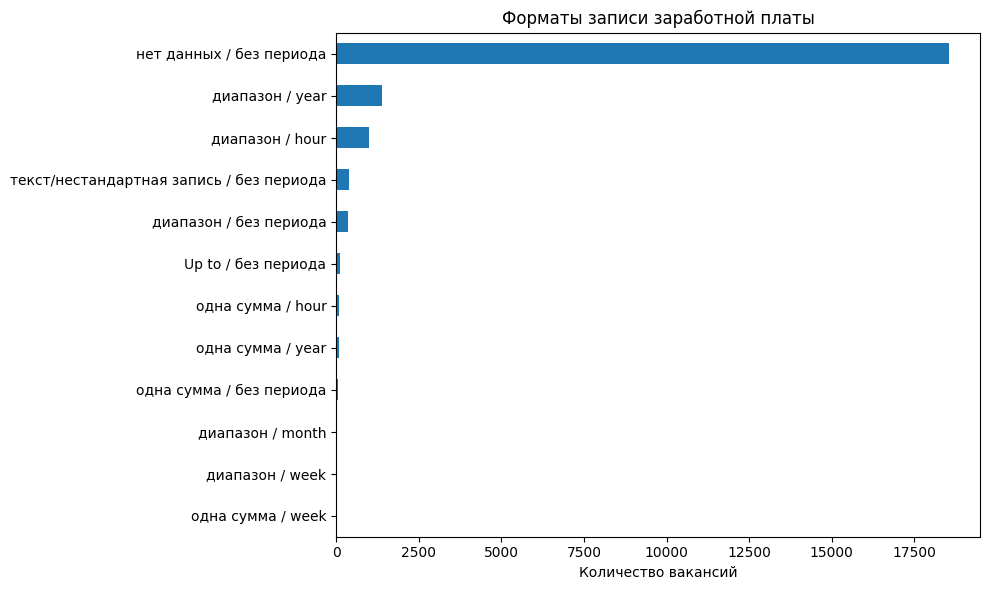

Нестандартные примеры без распознанного формата:


salary
Commensurate with Experience                                       38
DOE                                                                12
Competitive                                                        11
Based on experience                                                10
W-2, Weekly Paycheck, Great Compensation Package and Incentives    10
BOE                                                                 7
Based on Experience                                                 7
Salary commensurate with experience                                 5
Name: count, dtype: int64

In [10]:
salary_text = data["salary"].fillna("").astype(str).str.replace("\u00a0", " ", regex=False).str.strip()
NUMBER = r"(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?"

is_range = salary_text.str.match(rf"^\$?\s*{NUMBER}\s*[-–]\s*\$?\s*{NUMBER}")
is_up_to = salary_text.str.match(r"^Up\s+to\b", case=False)
is_single = salary_text.str.match(rf"^\$?\s*{NUMBER}") & ~is_range

# Период иногда не указан. Иногда есть поясняющий текст в конце.
salary_period = salary_text.str.extract(r"/\s*(hour|year|month|week)\b", flags=re.IGNORECASE)[0].str.lower()
salary_kind = pd.Series("текст/нестандартная запись", index=data.index)
salary_kind.loc[salary_text.eq("")] = "нет данных"
salary_kind.loc[is_single] = "одна сумма"
salary_kind.loc[is_range] = "диапазон"
salary_kind.loc[is_up_to] = "Up to"

salary_format = salary_kind + " / " + salary_period.fillna("без периода")
format_salary_counts = salary_format.value_counts()
display(format_salary_counts.rename("Количество").to_frame())
format_salary_counts.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title("Форматы записи заработной платы")
plt.xlabel("Количество вакансий")
plt.tight_layout()
plt.show()
print("Нестандартные примеры без распознанного формата:")
display(salary_text.loc[salary_kind.eq("текст/нестандартная запись")].value_counts().head(8))


#### Задание 2.2

1. Разделите столбец `salary` зарплаты три: `минимальная граница зарплаты`, `максимальная граница зарплаты`, `период`. Если значение суммы указано только одно, считайте, что это минимальная зарплата. Значение суммы в обоих столбцах преобразуйте в формат `float`.
2. Покажите на столбчатой диаграмме с группировкой среднюю и медианную минимальную зарплату в каждом периоде. Сделайте выводы.

Количество зарплат с распознанной суммой: 3051


,salary,минимальная граница зарплаты,максимальная граница зарплаты,период
21309,20.00 - 25.00 $ /hour,20.0,25.0,hour
4250,"0.00 - 36,000.00 $ /year",0.0,36000.0,year
14007,"38,000.00 - 45,000.00 $ /year",38000.0,45000.0,year
7387,15.00 - 15.00 $ /hour,15.0,15.0,hour
1535,"95,000.00 - 105,000.00 $ /year",95000.0,105000.0,year
1675,"75,000.00 - 85,000.00 $ /year",75000.0,85000.0,year
14433,30.00 - 30.00 $ /hour,30.0,30.0,hour
21837,"110,000.00 - 150,000.00 $ /year",110000.0,150000.0,year


,mean,median
период,,
hour,201.81,15.65
month,6113.93,4902.61
week,662.40,600.00
year,60031.80,60000.00


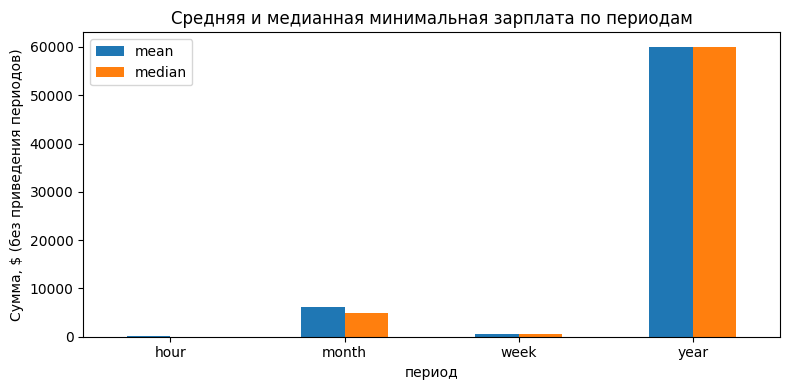

Вывод: зарплаты за год значительно выше почасовых; сравнивать суммы напрямую без учёта периода нельзя.


In [11]:
# Из строк извлекаем числа: нижнюю границу, верхнюю границу и период.
number_with_dollar = rf"\$?\s*({NUMBER})"
range_numbers = salary_text.str.extract(
    rf"^\s*{number_with_dollar}\s*[-–]\s*{number_with_dollar}"
)
single_number = salary_text.str.extract(rf"^\s*{number_with_dollar}")[0]
up_to_number = salary_text.str.extract(rf"(?i:^\s*Up\s+to\s*){number_with_dollar}")[0]

# По условию задания при одной сумме записываем её в минимальную границу.
min_salary = single_number.fillna(up_to_number)
max_salary = range_numbers[1]
clean["минимальная граница зарплаты"] = pd.to_numeric(min_salary.str.replace(",", "", regex=False), errors="coerce")
clean["максимальная граница зарплаты"] = pd.to_numeric(max_salary.str.replace(",", "", regex=False), errors="coerce")
clean["период"] = salary_period

print("Количество зарплат с распознанной суммой:", clean["минимальная граница зарплаты"].notna().sum())
display(clean.loc[clean["минимальная граница зарплаты"].notna(),
                  ["salary", "минимальная граница зарплаты", "максимальная граница зарплаты", "период"]].sample(8, random_state=17))

stats_salary = clean.dropna(subset=["минимальная граница зарплаты", "период"]).groupby("период")["минимальная граница зарплаты"].agg(["mean", "median"])
display(stats_salary.round(2))
stats_salary.plot(kind="bar", figsize=(8, 4))
plt.title("Средняя и медианная минимальная зарплата по периодам")
plt.ylabel("Сумма, $ (без приведения периодов)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Вывод: зарплаты за год значительно выше почасовых; сравнивать суммы напрямую без учёта периода нельзя.")


#### Задание 2.3

Как было отмечено в задании 2.1, период, за который указывается зарплата, может отсутствовать. Восполните этот пробел в данных следующим образом:

1. Определите диапазон изменения (разброс) значений денежной суммы за каждый из встречающихся в данных периодов. Постройте гистограмму для каждого периода. Сопоставьте результаты с результатами в задании 2.2.
2. Определите, к среднему значению за какой период ближе всего сумма, у которой период не указан. Укажите для найденный период. В спорных случаях, где сумма одинаково близка к нескольким диапазонам, не выбирайте ничего. Учтите, что в данных могут быть выбросы.

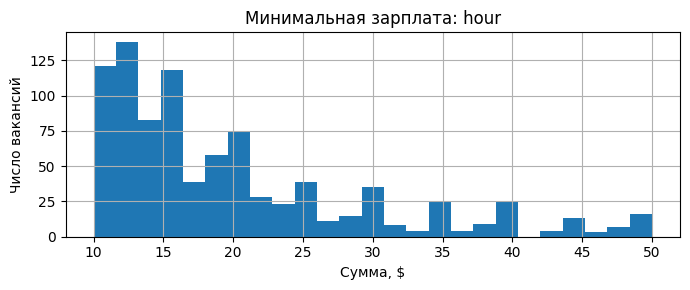

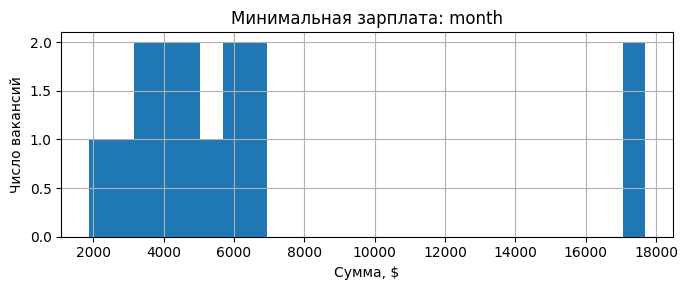

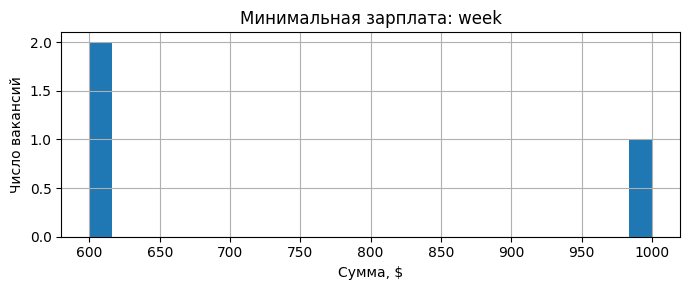

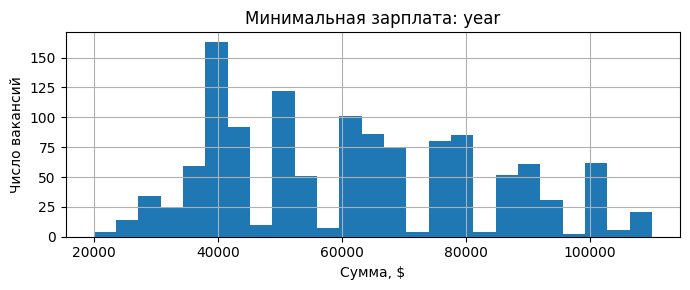

,нижние 5%,верхние 5%,среднее без выбросов
hour,10.0,50.00,19.82
month,1858.5,17688.94,6401.53
week,129.6,1080.00,733.33
year,20000.0,110000.00,61673.11


Сумм без указанного периода: 518
Удалось осторожно восстановить период: 472
Если надёжно определить период нельзя, пропуск сохранён.


In [12]:
# Смотрим разброс для каждого периода. Отсекаем нижние и верхние 5% как выбросы.
period_stats = {}
for period, group in clean.dropna(subset=["минимальная граница зарплаты", "период"]).groupby("период"):
    # Нулевая оплата нередко означает заполнитель, а не реальную зарплату.
    values = group.loc[group["минимальная граница зарплаты"] > 1, "минимальная граница зарплаты"]
    lo, hi = values.quantile([0.05, 0.95])
    typical = values[values.between(lo, hi)]
    period_stats[period] = {"нижние 5%": lo, "верхние 5%": hi, "среднее без выбросов": typical.mean()}

    plt.figure(figsize=(7, 3))
    typical.hist(bins=25)
    plt.title(f"Минимальная зарплата: {period}")
    plt.xlabel("Сумма, $")
    plt.ylabel("Число вакансий")
    plt.tight_layout()
    plt.show()

period_stats = pd.DataFrame(period_stats).T
display(period_stats.round(2))

# Если период отсутствует, ищем наиболее близкую типичную зарплату.
# Когда сумма подходит сразу к нескольким периодам почти одинаково, оставляем пропуск.
def guess_period(amount):
    if pd.isna(amount):
        return pd.NA
    candidates = period_stats[
        (period_stats["нижние 5%"] <= amount) & (period_stats["верхние 5%"] >= amount)
    ]
    if candidates.empty:
        return pd.NA
    distances = (candidates["среднее без выбросов"] - amount).abs().sort_values()
    if len(distances) > 1 and distances.iloc[1] <= distances.iloc[0] * 1.5:
        return pd.NA
    return distances.index[0]

unknown_period = clean["период"].isna() & clean["минимальная граница зарплаты"].notna()
guessed = clean.loc[unknown_period, "минимальная граница зарплаты"].apply(guess_period)
clean["период_восстановленный"] = clean["период"].copy()
clean.loc[unknown_period, "период_восстановленный"] = guessed
print("Сумм без указанного периода:", unknown_period.sum())
print("Удалось осторожно восстановить период:", guessed.notna().sum())
print("Если надёжно определить период нельзя, пропуск сохранён.")


### Задание 3

В задании 3 необходимо провести обработку столбца `job_type`. Выясните, какие форматы значений есть в столбце `job_type`. Сделайте выводы. При необходимости – стройте графики.

In [13]:
print("Количество исходных вариантов job_type:", data["job_type"].nunique())
display(data["job_type"].value_counts(dropna=False).to_frame("Количество").head(40))
print("Вывод: Full Time Employee, Full Time, Employee и другие варианты означают одно и то же.")
print("Также встречаются пропуски и особые виды занятости: контрактная, сезонная, стажировка.")


Количество исходных вариантов job_type: 39


,Количество
job_type,
Full Time,6757
Full Time Employee,6617
"Full Time, Employee",3360
NaN,1628
Full Time Temporary/Contract/Project,1062
"Full Time, Temporary/Contract/Project",533
"Full Time , Employee",406
Part Time Employee,382
Part Time,329


Вывод: Full Time Employee, Full Time, Employee и другие варианты означают одно и то же.
Также встречаются пропуски и особые виды занятости: контрактная, сезонная, стажировка.


Вы заметили, что многие значения фактически одинаковые, но немного по-разному отформатированы? Приведем их к единому формату.

In [14]:
# Убираем лишние слова, пробелы, разные разделители.
job_type_clean = data["job_type"].fillna("").astype(str)
job_type_clean = job_type_clean.str.replace("\u00a0", " ", regex=False)
job_type_clean = job_type_clean.str.replace(r"^\s*Job Type\s*", "", regex=True, case=False)
job_type_clean = job_type_clean.str.replace(">", "", regex=False)
job_type_clean = job_type_clean.str.replace(r"\s*/\s*(?=Employee|Intern|Temporary)", ", ", regex=True)
job_type_clean = job_type_clean.str.replace(r"\s*,\s*", ", ", regex=True)
job_type_clean = job_type_clean.str.replace(r"\s+", " ", regex=True).str.strip(" ,")
clean["job_type_очищенный"] = job_type_clean.replace("", pd.NA)
print("Количество вариантов после базовой очистки:", clean["job_type_очищенный"].nunique())
display(clean["job_type_очищенный"].value_counts(dropna=False).head(15))


Количество вариантов после базовой очистки: 21


job_type_очищенный
Full Time                                6773
Full Time Employee                       6637
Full Time, Employee                      3901
<NA>                                     1628
Full Time Temporary/Contract/Project     1064
Full Time, Temporary/Contract/Project     590
Part Time Employee                        384
Part Time                                 330
Part Time, Employee                       202
Temporary/Contract/Project                193
Employee                                  148
Part Time, Temporary/Contract/Project      51
Per Diem, Employee                         29
Per Diem                                   22
Part Time Seasonal                         17
Name: count, dtype: int64

Столбец `job_type` состоит из двух частей: "полнота" занятости (`Full Time`, `Part Time`, `Per Diem`) и "тип" занятости (`Employee`, `Intern`). Кроме того, встречаются и неполные записи.

Задание:
1. Написать одно или несколько регулярных выражений для разделения столбца `job_type` на два: `полнота занятости`, `тип занятости`.
2. Если данные о полноте отсутствуют, внесите значение `Full Time`.
Если отсутствуют данные о типе – внесите `Employee`.
3. Постройте столбчатую диаграмму со стековой группировкой для полноты и типа занятости. Сделайте выводы.

Получившиеся варианты занятости:


,Количество
job_type_единый,
"Full Time, Employee",19088
"Full Time, Temporary/Contract/Project",1847
"Part Time, Employee",916
"Per Diem, Employee",63
"Part Time, Temporary/Contract/Project",57
"Part Time, Seasonal",17
"Full Time, Intern",5
"Per Diem, Temporary/Contract/Project",4
"Part Time, Intern",3


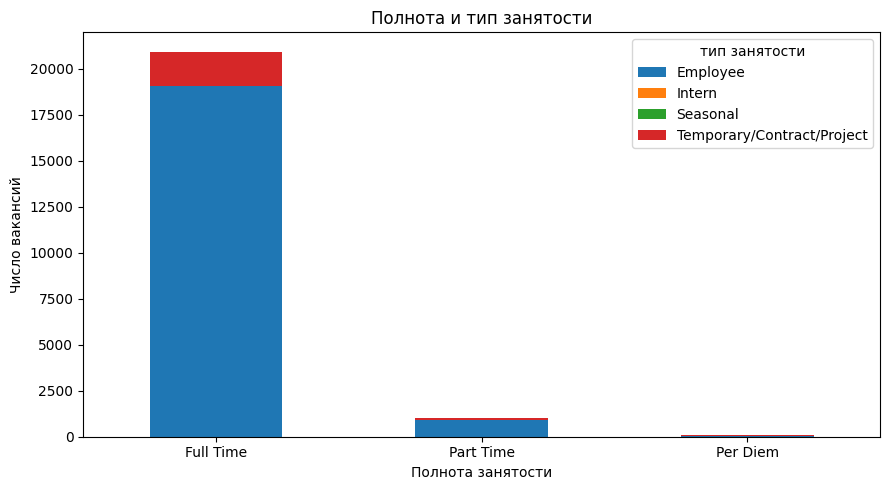

Вывод: чаще всего встречаются полная занятость и работа по найму (Employee).
Контрактная работа и стажировки оставлены отдельными категориями, чтобы не потерять информацию.
Итоговый датасет: (22000, 25)


,location,город,код штата,почтовый индекс,salary,минимальная граница зарплаты,максимальная граница зарплаты,период_восстановленный,job_type_единый
0,"Madison, WI 53702",Madison,WI,53702,NaN,NaN,NaN,NaN,"Full Time, Employee"
1,"Madison, WI 53708",Madison,WI,53708,NaN,NaN,NaN,NaN,"Full Time, Employee"
2,DePuy Synthes Companies is a member of Johnson...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Full Time, Employee"
3,"Dixon, CA",Dixon,CA,<NA>,NaN,NaN,NaN,NaN,"Full Time, Employee"
4,"Camphill, PA",Camphill,PA,<NA>,NaN,NaN,NaN,NaN,"Full Time, Employee"
5,"Charlottesville, VA",Charlottesville,VA,<NA>,NaN,NaN,NaN,NaN,"Full Time, Employee"
6,Contact name Tony Zerio,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Full Time, Employee"
7,"Austin, TX 73301",Austin,TX,73301,NaN,NaN,NaN,NaN,"Full Time, Employee"
8,"Austin, TX 78746",Austin,TX,78746,NaN,NaN,NaN,NaN,"Part Time, Employee"
9,"Chesterfield, MO",Chesterfield,MO,<NA>,NaN,NaN,NaN,NaN,"Full Time, Employee"


In [15]:
# Разделение на полноту и тип занятости.
job = clean["job_type_очищенный"].fillna("")
fullness = job.str.extract(r"(Full\s*Time|Part\s*Time|Per\s*Diem)", flags=re.IGNORECASE)[0].str.title()
employment = job.str.extract(r"(Temporary/Contract/Project|Employee|Intern|Seasonal)", flags=re.IGNORECASE)[0]

# По условию отсутствующие значения заменяем наиболее типичными.
clean["полнота занятости"] = fullness.fillna("Full Time")
clean["тип занятости"] = employment.fillna("Employee")
clean["job_type_единый"] = clean["полнота занятости"] + ", " + clean["тип занятости"]

print("Получившиеся варианты занятости:")
display(clean["job_type_единый"].value_counts().to_frame("Количество"))

by_employment = pd.crosstab(clean["полнота занятости"], clean["тип занятости"])
by_employment.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Полнота и тип занятости")
plt.ylabel("Число вакансий")
plt.xlabel("Полнота занятости")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Вывод: чаще всего встречаются полная занятость и работа по найму (Employee).")
print("Контрактная работа и стажировки оставлены отдельными категориями, чтобы не потерять информацию.")

print("Итоговый датасет:", clean.shape)
display(clean[["location", "город", "код штата", "почтовый индекс",
               "salary", "минимальная граница зарплаты", "максимальная граница зарплаты",
               "период_восстановленный", "job_type_единый"]].head(10))


### Итоговые выводы

1. **Пропуски.** Удалять все неполные записи нельзя: данные почти полностью потеряются. Вместо этого мы сохраняем исходные строки и аккуратно извлекаем полезные признаки.
2. **Местоположение.** Основной формат — `город, штат, индекс` или `город, штат`. Нестандартные адреса частично удалось восстановить; неоднозначный текст оставлен без выдуманного города.
3. **Зарплата.** Суммы переведены в числа `float`, отделены границы диапазона и период. Неизвестный период восстанавливается только когда сумма попадает в типичный диапазон и нет близкой альтернативы.
4. **Тип занятости.** Убраны лишние пробелы и разные разделители, выделены полнота и тип занятости. Пропуски заменены значениями из условия, а контрактная и сезонная занятость сохранены как отдельные категории.

**Важно:** исправленные поля находятся в переменной `clean`. Исходный датасет `data` не изменялся. При защите можно показать таблицы, графики и сравнить значения до и после очистки.

# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения всех заданий в виде ссылки на Google Colab в новой ветке своего репозитория по первой лабораторной на GitHub. Открыть `pull request`.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой решение задачи на обработку данных лабораторной работы, меньшее по объему, но сопоставимое по сложности тем заданиям, которые требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. В столбце `sector` часто представлены данные из столбца `organization` и наоборот. Устраните эту проблему.
2. В столбце `job_title` часто можно частично или полностью встретить указание местоположения организации. Сравните, совпадают ли в таких случаях данные с тем, что указано в столбцах `город`, `код штата`, `почтовый индекс`. Если в этих трех столбцах данные отсутствуют, заполните их данными из столбца `job_title`.
3. Практически во всех столбцах датасета вместо соответствующих названию данных иногда встречается текст из `job_description`. Найдите такие столбцы и записи с описанием вакансии в них. Покажите на столбчатой диаграмме, в каких столбцах и в каком количестве находится информация из столбца `job_description`.

# Дополнительные материалы

1. DAMA-DMBOK: Свод знаний по управлению данными: Второе издание / DAMA International; [пер. с англ.]. – Москва: ООО "Олимп-Бизнес", 2021. – 828 с.
2. Макгрегор, С. Обработка данных на Python: Data Wrangling и Data Quality: [Текст] / С. Макгрегор. – Москва: БХВ, 2024. – 432 с.